In [1]:

# WeatherWise: Install the required libraries

!pip -q install gradio requests pandas scikit-learn matplotlib

print("All required libraries are ready!")


All required libraries are ready!


In [2]:

# STEP 2: Fetch a 7-day weather forecast

import requests
import pandas as pd

def get_weather_forecast(city):
    # Find the city's latitude and longitude
    geo_url = "https://geocoding-api.open-meteo.com/v1/search"
    geo_params = {
        "name": city,
        "count": 1,
        "language": "en",
        "format": "json"
    }

    geo_response = requests.get(geo_url, params=geo_params, timeout=20)
    geo_response.raise_for_status()
    geo_data = geo_response.json()

    if not geo_data.get("results"):
        print("City not found. Please try another city.")
        return None

    place = geo_data["results"][0]
    latitude = place["latitude"]
    longitude = place["longitude"]

    # Fetch the 7-day forecast
    weather_url = "https://api.open-meteo.com/v1/forecast"
    weather_params = {
        "latitude": latitude,
        "longitude": longitude,
        "daily": [
            "temperature_2m_max",
            "temperature_2m_min",
            "precipitation_probability_max",
            "weather_code"
        ],
        "timezone": "auto",
        "forecast_days": 7
    }

    weather_response = requests.get(
        weather_url, params=weather_params, timeout=20
    )
    weather_response.raise_for_status()
    weather_data = weather_response.json()

    forecast = pd.DataFrame({
        "Date": weather_data["daily"]["time"],
        "Max Temp (°C)": weather_data["daily"]["temperature_2m_max"],
        "Min Temp (°C)": weather_data["daily"]["temperature_2m_min"],
        "Rain Chance (%)": weather_data["daily"]["precipitation_probability_max"],
        "Weather Code": weather_data["daily"]["weather_code"]
    })

    print(f"7-day forecast for {place['name']}, "
          f"{place.get('country', '')}")
    return forecast


# Test the function
forecast = get_weather_forecast("Indore")

if forecast is not None:
    display(forecast)


7-day forecast for Indore, India


,Date,Max Temp (°C),Min Temp (°C),Rain Chance (%),Weather Code
0,2026-10-22,30.9,22.3,31,51
1,2026-10-23,31.6,22.1,0,3
2,2026-10-24,32.2,20.8,0,0
3,2026-10-25,31.9,21.7,0,0
4,2026-10-26,32.0,21.2,0,0
5,2026-10-27,31.8,21.1,2,0
6,2026-10-28,30.1,19.0,4,3


In [12]:

# STEP 3: Convert weather codes into readable descriptions

weather_descriptions = {
    0: "Clear Sky ☀️",
    1: "Mainly Clear 🌤️",
    2: "Partly Cloudy ⛅",
    3: "Overcast ☁️",
    45: "Fog 🌫️",
    48: "Depositing Rime Fog 🌫️",
    51: "Light Drizzle 🌦️",
    53: "Moderate Drizzle 🌦️",
    55: "Dense Drizzle 🌧️",
    61: "Slight Rain 🌧️",
    63: "Moderate Rain 🌧️",
    65: "Heavy Rain 🌧️",
    71: "Slight Snow ❄️",
    73: "Moderate Snow ❄️",
    75: "Heavy Snow ❄️",
    80: "Rain Showers 🌦️",
    81: "Moderate Rain Showers 🌧️",
    82: "Heavy Rain Showers 🌧️",
    95: "Thunderstorm ⛈️",
    96: "Thunderstorm with Hail ⛈️",
    99: "Severe Thunderstorm with Hail ⛈️"
}

forecast["Weather"] = forecast["Weather Code"].map(
    weather_descriptions
).fillna("Other Conditions")

display(forecast.drop(columns=["Weather Code"]))


,Date,Max Temp (°C),Min Temp (°C),Rain Chance (%),Weather
0,2026-10-22,30.9,22.3,31,Light Drizzle 🌦️
1,2026-10-23,31.6,22.1,0,Overcast ☁️
2,2026-10-24,32.2,20.8,0,Clear Sky ☀️
3,2026-10-25,31.9,21.7,0,Clear Sky ☀️
4,2026-10-26,32.0,21.2,0,Clear Sky ☀️
5,2026-10-27,31.8,21.1,2,Clear Sky ☀️
6,2026-10-28,30.1,19.0,4,Overcast ☁️


In [13]:

# STEP 4: Test the forecast for any city

city_name = input("Enter a city name: ")

new_forecast = get_weather_forecast(city_name)

if new_forecast is not None:
    new_forecast["Weather"] = new_forecast["Weather Code"].map(
        weather_descriptions
    ).fillna("Other Conditions")

    display(new_forecast.drop(columns=["Weather Code"]))


Enter a city name: delhi
7-day forecast for Delhi, India


,Date,Max Temp (°C),Min Temp (°C),Rain Chance (%),Weather
0,2026-10-22,30.3,20.2,0,Clear Sky ☀️
1,2026-10-23,30.5,20.7,18,Light Drizzle 🌦️
2,2026-10-24,30.8,19.5,10,Mainly Clear 🌤️
3,2026-10-25,31.1,19.1,2,Clear Sky ☀️
4,2026-10-26,30.8,18.4,0,Clear Sky ☀️
5,2026-10-27,30.6,18.4,0,Clear Sky ☀️
6,2026-10-28,30.7,17.9,0,Overcast ☁️


In [22]:

# STEP 5: Build the WeatherWise Fancy Dashboard

import gradio as gr
import pandas as pd
import html


def weather_icon(code):
    code = int(code)

    if code == 0:
        return "☀️"
    elif code == 1:
        return "🌤️"
    elif code in [2]:
        return "⛅"
    elif code == 3:
        return "☁️"
    elif code in [45, 48]:
        return "🌫️"
    elif code in [51, 53, 55, 56, 57]:
        return "🌦️"
    elif code in [61, 63, 65, 66, 67, 80, 81, 82]:
        return "🌧️"
    elif code in [71, 73, 75, 77, 85, 86]:
        return "❄️"
    elif code >= 95:
        return "⛈️"

    return "🌥️"


def make_dashboard(city):
    if not city or not city.strip():
        return "<h3>Please enter a city name.</h3>"

    try:
        data = get_weather_forecast(city.strip())

        if data is None or data.empty:
            return "<h3>City not found. Please try another city.</h3>"

        cards = ""

        for _, row in data.iterrows():
            code = int(row["Weather Code"])
            desc = weather_descriptions.get(code, "Other Conditions")
            date = pd.to_datetime(row["Date"]).strftime("%a, %d %b")

            maximum = row["Max Temp (°C)"]
            minimum = row["Min Temp (°C)"]
            rain = row["Rain Chance (%)"]

            maximum = "—" if pd.isna(maximum) else f"{maximum:.1f}°"
            minimum = "—" if pd.isna(minimum) else f"{minimum:.1f}°"
            rain = "—" if pd.isna(rain) else f"{rain:.0f}%"

            cards += f"""
            <div class="day-card">
                <div class="day-date">{date}</div>
                <div class="day-icon">{weather_icon(code)}</div>
                <div class="day-condition">{html.escape(str(desc))}</div>
                <div class="day-temp">{maximum}</div>
                <div class="day-low">Low {minimum}</div>
                <div class="day-rain">💧 {rain} rain chance</div>
            </div>
            """

        first = data.iloc[0]
        first_code = int(first["Weather Code"])
        description = weather_descriptions.get(
            first_code, "Other Conditions"
        )

        high = first["Max Temp (°C)"]
        low = first["Min Temp (°C)"]
        rain = first["Rain Chance (%)"]

        high = "—" if pd.isna(high) else f"{high:.1f}°"
        low = "—" if pd.isna(low) else f"{low:.1f}°"
        rain = "—" if pd.isna(rain) else f"{rain:.0f}%"

        safe_city = html.escape(city.strip())
        safe_description = html.escape(str(description))
        safe_date = html.escape(str(first["Date"]))

        return f"""
        <div class="weather-page">
            <div class="hero">
                <div class="hero-top">YOUR WEATHER OVERVIEW</div>
                <div class="hero-city">📍 {safe_city}</div>
                <div class="hero-date">{safe_date}</div>

                <div class="hero-main">
                    <div>
                        <div class="hero-temp">{high}</div>
                        <div class="hero-desc">{safe_description}</div>
                        <div class="hero-range">Low {low}</div>
                    </div>
                    <div class="hero-icon">{weather_icon(first_code)}</div>
                </div>

                <div class="hero-stats">
                    <div class="stat">
                        <span>🌡️</span>
                        <small>Highest</small>
                        <b>{high}</b>
                    </div>
                    <div class="stat">
                        <span>❄️</span>
                        <small>Lowest</small>
                        <b>{low}</b>
                    </div>
                    <div class="stat">
                        <span>💧</span>
                        <small>Rain chance</small>
                        <b>{rain}</b>
                    </div>
                </div>
            </div>

            <div class="section-title">The week ahead <span>✦</span></div>
            <div class="forecast-grid">{cards}</div>

            <div class="footer-note">
                Weather data powered by Open-Meteo · Forecast values may change
            </div>
        </div>
        """

    except Exception as e:
        print(f"Weather dashboard error: {e}")
        return """
        <div class="error-card">
            <h3>Oops! We couldn't load the forecast.</h3>
            <p>Please check the city name and try again.</p>
        </div>
        """


# Dashboard styling
css = """
.gradio-container {
    background: #0b1224 !important;
    color: #f4f7ff !important;
}
.gradio-container .prose h1,
.gradio-container .prose p {
    color: #f4f7ff !important;
}
#weather-output {
    border: none !important;
    background: transparent !important;
}
.weather-page {
    font-family: Inter, sans-serif;
    color: #f4f7ff;
    padding: 10px 0 25px;
}
.hero {
    padding: 30px;
    border-radius: 25px;
    background: linear-gradient(135deg, #193b62, #4c4d83 60%, #82639b);
    box-shadow: 0 15px 45px rgba(0,0,0,.22);
}
.hero-top {
    font-size: 11px;
    letter-spacing: 3px;
    color: #c5d9f4;
}
.hero-city {
    font-size: 27px;
    font-weight: 700;
    margin-top: 15px;
}
.hero-date {
    color: #d2d9f0;
    margin-top: 5px;
    font-size: 13px;
}
.hero-main {
    display: flex;
    justify-content: space-between;
    align-items: center;
    padding: 20px 0;
}
.hero-temp {
    font-size: 66px;
    font-weight: 750;
    letter-spacing: -3px;
}
.hero-desc {
    font-size: 17px;
    color: #e3eafa;
}
.hero-range {
    color: #c5d9f4;
    margin-top: 8px;
}
.hero-icon {
    font-size: 85px;
    filter: drop-shadow(0 5px 12px #243451);
}
.hero-stats {
    display: grid;
    grid-template-columns: repeat(3, 1fr);
    gap: 12px;
    margin-top: 8px;
}
.stat {
    background: rgba(255,255,255,.12);
    border: 1px solid rgba(255,255,255,.14);
    border-radius: 16px;
    padding: 15px;
    display: flex;
    flex-direction: column;
    gap: 7px;
}
.stat span { font-size: 20px; }
.stat small { color: #d2d9f0; }
.stat b { font-size: 19px; }
.section-title {
    font-size: 22px;
    font-weight: 700;
    margin: 30px 0 16px;
}
.section-title span { color: #91caff; }
.forecast-grid {
    display: grid;
    grid-template-columns: repeat(4, minmax(0, 1fr));
    gap: 12px;
}
.day-card {
    background: linear-gradient(160deg, #182945, #121e34);
    border: 1px solid #2c405e;
    border-radius: 18px;
    padding: 17px 10px;
    text-align: center;
    min-width: 0;
    transition: transform .2s, border-color .2s;
}
.day-card:hover {
    transform: translateY(-4px);
    border-color: #83caff;
}
.day-date { color: #b6c9e5; font-size: 12px; }
.day-icon { font-size: 35px; margin: 12px 0; }
.day-condition {
    font-size: 12px;
    color: #d2dff1;
    min-height: 30px;
}
.day-temp { font-size: 23px; font-weight: 700; margin-top: 10px; }
.day-low { color: #9eafc9; font-size: 12px; margin-top: 5px; }
.day-rain { color: #8ecbff; font-size: 11px; margin-top: 12px; }
.footer-note {
    color: #8fa2bf;
    font-size: 11px;
    margin-top: 22px;
    text-align: center;
}
.error-card {
    background: #182945;
    color: #f4f7ff;
    padding: 24px;
    border-radius: 16px;
}
@media (max-width: 600px) {
    .hero { padding: 22px; }
    .hero-temp { font-size: 53px; }
    .hero-icon { font-size: 62px; }
    .forecast-grid { grid-template-columns: repeat(2, minmax(0, 1fr)); }
    .stat { padding: 10px; }
}
"""

# Create the Gradio application
with gr.Blocks(
    theme=gr.themes.Base(),
    css=css + ml_css,
    title="WeatherWise | Forecast"
) as app:

    gr.Markdown(
        "# 🌦️ WeatherWise\n"
        "### A little sunshine, wherever you are."
    )

    with gr.Row():
        city_input = gr.Textbox(
            label="Search your city",
            placeholder="Try Indore, Mumbai, Delhi...",
            scale=4
        )

        search_btn = gr.Button(
            "✨ Get Forecast",
            variant="primary",
            scale=1
        )

    output = gr.HTML(elem_id="weather-output")

    search_btn.click(
        fn=make_dashboard_with_ml,
        inputs=city_input,
        outputs=output
    )

    city_input.submit(
        fn=make_dashboard,
        inputs=city_input,
        outputs=output
    )

    gr.Examples(
        examples=[["Indore"], ["Mumbai"], ["Delhi"], ["Jaipur"]],
        inputs=city_input
    )

app.launch(share=True)


/tmp/ipykernel_5079/232430544.py:278: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://a49c93981b006d0c55.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [17]:

# STEP 6: Load Historical Weather Data for Machine Learning

import pandas as pd

dataset_url = "https://rattle.togaware.com/weatherAUS.csv"

weather_df = pd.read_csv(dataset_url)

print("Historical dataset loaded successfully!")
print("Dataset shape:", weather_df.shape)

print("\nAvailable columns:")
print(weather_df.columns.tolist())

display(weather_df.head())


Historical dataset loaded successfully!
Dataset shape: (275410, 24)

Available columns:
['Date', 'Location', 'MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustDir', 'WindGustSpeed', 'WindDir9am', 'WindDir3pm', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm', 'RainToday', 'RISK_MM', 'RainTomorrow']


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RISK_MM,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,0.0,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,0.0,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,0.0,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,1.0,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,0.2,No


Model training completed!
Training samples: 213853
Testing samples: 53464
Accuracy: 83.96%

Classification Report:
              precision    recall  f1-score   support

     No Rain       0.86      0.95      0.90     41679
        Rain       0.72      0.45      0.55     11785

    accuracy                           0.84     53464
   macro avg       0.79      0.70      0.73     53464
weighted avg       0.83      0.84      0.83     53464



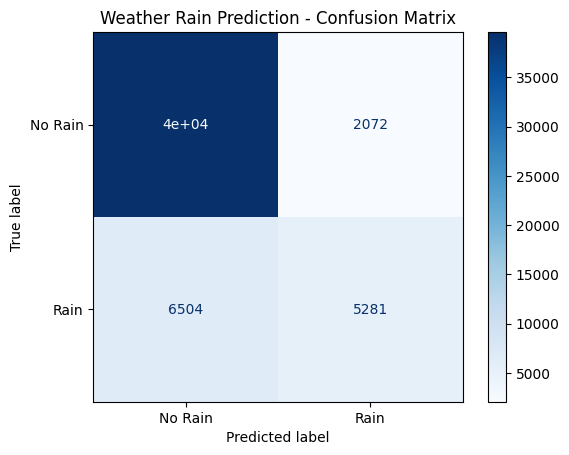

In [18]:

# STEP 7: Train and Evaluate the Rain Prediction Model

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Select useful weather features
features = [
    "MinTemp",
    "MaxTemp",
    "Rainfall",
    "Humidity3pm",
    "Pressure3pm",
    "WindSpeed3pm"
]

# Prepare the dataset
ml_data = weather_df[features + ["RainTomorrow"]].dropna(
    subset=["RainTomorrow"]
).copy()

X = ml_data[features]
y = ml_data["RainTomorrow"].map({"No": 0, "Yes": 1})

# Remove any rows with unexpected target values
valid = y.notna()
X = X.loc[valid]
y = y.loc[valid].astype(int)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Build and train the model
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

# Evaluate the model
y_pred = model.predict(X_test)

print("Model training completed!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print(f"Accuracy: {accuracy_score(y_test, y_pred):.2%}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["No Rain", "Rain"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Rain", "Rain"],
    cmap="Blues"
)
plt.title("Weather Rain Prediction - Confusion Matrix")
plt.show()


In [19]:

# STEP 8: Create the Rain Prediction Function

def predict_rain(min_temp, max_temp, rainfall,
                 humidity, pressure, wind_speed):

    input_data = pd.DataFrame([{
        "MinTemp": min_temp,
        "MaxTemp": max_temp,
        "Rainfall": rainfall,
        "Humidity3pm": humidity,
        "Pressure3pm": pressure,
        "WindSpeed3pm": wind_speed
    }])

    prediction = model.predict(input_data)[0]
    probability = model.predict_proba(input_data)[0][1]

    result = "Rain likely 🌧️" if prediction == 1 else "No rain predicted ☀️"

    return result, round(float(probability) * 100, 1)


# Test the function
result, probability = predict_rain(
    min_temp=18,
    max_temp=30,
    rainfall=0,
    humidity=45,
    pressure=1012,
    wind_speed=15
)

print("Prediction:", result)
print("Model-estimated rain probability:", probability, "%")


Prediction: No rain predicted ☀️
Model-estimated rain probability: 1.0 %


In [20]:

# STEP 9: Dashboard with ML Rain Prediction

def make_dashboard_with_ml(city):
    if not city or not city.strip():
        return "<h3>Please enter a city name.</h3>"

    try:
        data = get_weather_forecast(city.strip())

        if data is None or data.empty:
            return "<h3>City not found. Please try another city.</h3>"

        # Get the first day's forecast
        first = data.iloc[0]

        # Weather API values do not include all six ML features.
        # Use the available values and clearly label assumptions.
        result, probability = predict_rain(
            min_temp=float(first["Min Temp (°C)"]),
            max_temp=float(first["Max Temp (°C)"]),
            rainfall=0.0,
            humidity=50.0,
            pressure=1012.0,
            wind_speed=15.0
        )

        rain_card = f"""
        <div class="ml-card">
            <div class="ml-label">🤖 ML RAIN PREDICTION</div>
            <div class="ml-result">{html.escape(result)}</div>
            <div class="ml-probability">
                Model-estimated probability: {probability}%
            </div>
            <p class="ml-note">
                Demonstration only: humidity, pressure, wind speed and
                rainfall are example assumptions. The model was trained
                on Australian historical weather data.
            </p>
        </div>
        """

        # Reuse the existing dashboard HTML and insert the ML card
        dashboard = make_dashboard(city)
        marker = '<div class="section-title">The week ahead'

        if marker in dashboard:
            dashboard = dashboard.replace(
                marker,
                rain_card + marker,
                1
            )

        return dashboard

    except Exception as e:
        print("Dashboard error:", e)
        return "<h3>Could not load the dashboard. Please try again.</h3>"


# Add styling for the ML prediction card
ml_css = """
.ml-card {
    background: linear-gradient(135deg, #183a50, #243454);
    border: 1px solid #426783;
    border-radius: 18px;
    padding: 22px;
    margin: 20px 0;
    color: #f4f7ff;
}
.ml-label {
    color: #9bd7ff;
    font-size: 12px;
    letter-spacing: 2px;
}
.ml-result {
    font-size: 24px;
    font-weight: 700;
    margin: 12px 0;
}
.ml-probability {
    font-size: 16px;
}
.ml-note {
    color: #c3d2e6;
    font-size: 12px;
    margin-top: 14px;
}
"""

print("ML dashboard function created successfully!")
print("Next, we will connect it to the Gradio interface.")


ML dashboard function created successfully!
Next, we will connect it to the Gradio interface.
